# ¿Cuánto CO₂ emite una persona según lo rica que es su país?

Proyecto sobre la sección **"Per capita CO₂ emissions"** del artículo [CO₂ emissions](https://ourworldindata.org/co2-emissions) de Our World in Data (Hannah Ritchie y Max Roser).

El artículo sostiene que la prosperidad es el principal motor de las emisiones por persona, pero que las decisiones de política y de tecnología también pesan: Francia, Reino Unido y Portugal emiten bastante menos por habitante que Alemania, Países Bajos o Bélgica con niveles de vida parecidos, sobre todo por la mezcla de energía que usan. Este notebook pone esa idea a prueba con datos y una regresión lineal.

**Preguntas**
1. ¿Cuánto sube el CO₂ por persona cuando sube el ingreso por persona?
2. ¿Cuánto mejora la predicción si además conocemos cuánta energía usa cada persona?
3. ¿Qué países se salen de lo que predice el ingreso, y por qué?

**Datos:** base completa de CO₂ y gases de efecto invernadero de Our World in Data ([github.com/owid/co2-data](https://github.com/owid/co2-data)), la que enlaza el propio artículo. Licencia CC BY.

## 1. Preparación y descarga de datos

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
ARCHIVO = "owid-co2-data.csv"

# Si el archivo ya está en la carpeta se usa tal cual; si no, se descarga y se guarda.
if os.path.exists(ARCHIVO):
    raw = pd.read_csv(ARCHIVO)
else:
    raw = pd.read_csv(URL)
    raw.to_csv(ARCHIVO, index=False)

print(f"Filas: {raw.shape[0]:,}  |  Columnas: {raw.shape[1]}")
raw.head()

Filas: 56,269  |  Columnas: 79


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


La tabla trae países, pero también regiones y totales mundiales mezclados en la misma columna `country` (por ejemplo "World", "Asia" o "High-income countries"). Si no se separan, un modelo trataría a "Asia" como si fuera un país más. Lo primero que hay que mirar es qué columnas sirven y cuánto falta en cada una.

In [2]:
usar = ["country", "year", "iso_code", "population", "gdp", "co2_per_capita", "energy_per_capita"]
explora = raw[usar].copy()

print("Rango de años:", explora["year"].min(), "-", explora["year"].max())
print("\nPorcentaje de datos faltantes por columna:")
print((explora.isna().mean() * 100).round(1).sort_values(ascending=False))

Rango de años: 1750 - 2025

Porcentaje de datos faltantes por columna:
energy_per_capita    80.9
gdp                  72.7
co2_per_capita       51.6
population           21.6
iso_code             14.2
year                  0.0
country               0.0
dtype: float64


`gdp` es el PIB total en dólares internacionales (precios de 2011), y `energy_per_capita` es la energía primaria consumida por persona en kWh. El PIB solo existe desde 1990 para la mayoría de países, así que ese es el punto de partida razonable.

## 2. Limpieza

In [3]:
registro = []   # (paso, filas que quedan)

df = raw[usar].copy()
registro.append(("Datos originales", len(df)))

# 1. Quitar regiones y agregados: los países tienen código ISO de 3 letras, los demás no.
df = df[df["iso_code"].notna() & ~df["iso_code"].astype(str).str.startswith("OWID")]
registro.append(("Solo países (sin regiones ni 'World')", len(df)))

# 2. El PIB solo es confiable desde 1990.
df = df[df["year"] >= 1990]
registro.append(("Años desde 1990", len(df)))

# 3. Quedarse con filas completas en las variables del análisis.
df = df.dropna(subset=["population", "gdp", "co2_per_capita", "energy_per_capita"])
registro.append(("Sin datos faltantes", len(df)))

# 4. Países muy pequeños distorsionan el promedio; se exige al menos 1 millón de habitantes.
df = df[df["population"] >= 1_000_000]
registro.append(("Población de 1 millón o más", len(df)))

# 5. Variables derivadas. El logaritmo hace falta porque ingreso y emisiones
#    crecen en proporciones, no en cantidades fijas.
df["gdp_per_capita"] = df["gdp"] / df["population"]
df = df[(df["gdp_per_capita"] > 0) & (df["co2_per_capita"] > 0) & (df["energy_per_capita"] > 0)]
registro.append(("Valores positivos (para poder usar logaritmos)", len(df)))

df["log_gdp_pc"] = np.log(df["gdp_per_capita"])
df["log_co2_pc"] = np.log(df["co2_per_capita"])
df["log_energy_pc"] = np.log(df["energy_per_capita"])
df = df.reset_index(drop=True)

pd.DataFrame(registro, columns=["Paso", "Filas restantes"])

,Paso,Filas restantes
0,Datos originales,56269
1,Solo países (sin regiones ni 'World'),48306
2,Años desde 1990,8028
3,Sin datos faltantes,5358
4,Población de 1 millón o más,4912
5,Valores positivos (para poder usar logaritmos),4912


In [4]:
print(f"Países en el análisis: {df['country'].nunique()}")
print(f"Años: {df['year'].min()} a {df['year'].max()}")
print(f"Duplicados país-año: {df.duplicated(['country', 'year']).sum()}")
df[["gdp_per_capita", "co2_per_capita", "energy_per_capita"]].describe().round(2)

Países en el análisis: 153
Años: 1990 a 2022
Duplicados país-año: 0


,gdp_per_capita,co2_per_capita,energy_per_capita
count,4912.00,4912.00,4912.00
mean,14234.69,4.70,23570.95
std,16443.46,7.72,31788.26
min,361.19,0.02,96.15
25%,2764.95,0.55,2426.86
50%,8239.62,2.50,11250.63
75%,20305.08,6.82,32949.88
max,163531.40,364.85,245295.05


Las emisiones por persona van de casi nada hasta decenas de toneladas, con una cola larga hacia arriba. Esa asimetría es la razón de trabajar en escala logarítmica.

## 3. Visualización

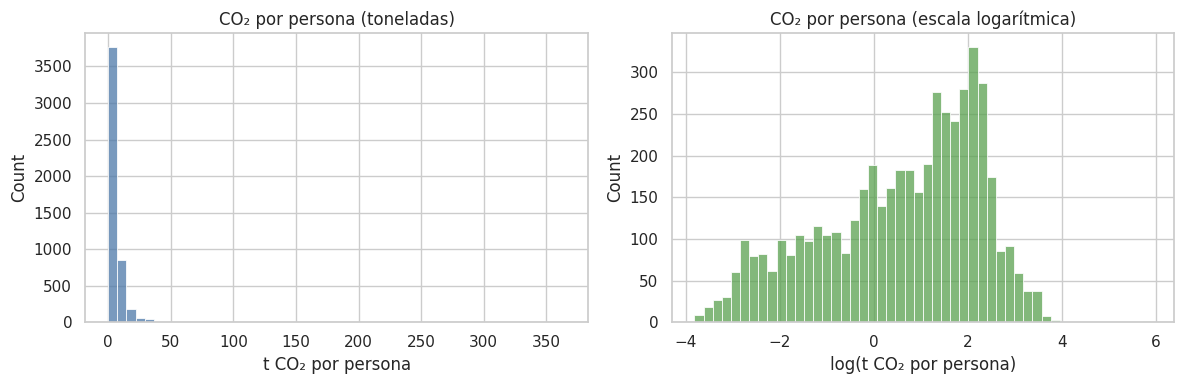

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["co2_per_capita"], bins=50, ax=ax[0], color="#4c78a8")
ax[0].set_title("CO₂ por persona (toneladas)")
ax[0].set_xlabel("t CO₂ por persona")
sns.histplot(df["log_co2_pc"], bins=50, ax=ax[1], color="#59a14f")
ax[1].set_title("CO₂ por persona (escala logarítmica)")
ax[1].set_xlabel("log(t CO₂ por persona)")
plt.tight_layout()
plt.show()

A la izquierda casi todos los países se amontonan en valores bajos y unos pocos se disparan. A la derecha, con logaritmo, la distribución queda mucho más pareja y se presta para una regresión lineal.

Año de referencia: 2022  (153 países)


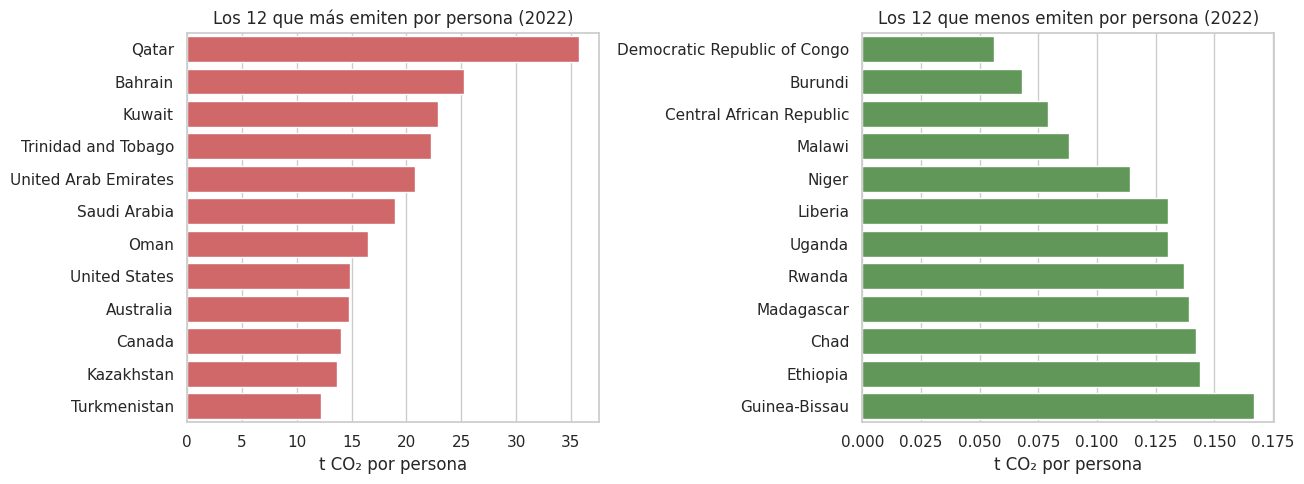

In [6]:
# Último año con buena cobertura (al menos 80 % del máximo de países con datos completos)
cobertura = df.groupby("year").size()
ultimo_anio = cobertura[cobertura >= 0.8 * cobertura.max()].index.max()
actual = df[df["year"] == ultimo_anio].copy()
print(f"Año de referencia: {ultimo_anio}  ({len(actual)} países)")

top = actual.nlargest(12, "co2_per_capita")
bajo = actual.nsmallest(12, "co2_per_capita")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=top, y="country", x="co2_per_capita", ax=ax[0], color="#e15759")
ax[0].set_title(f"Los 12 que más emiten por persona ({ultimo_anio})")
ax[0].set_xlabel("t CO₂ por persona"); ax[0].set_ylabel("")
sns.barplot(data=bajo, y="country", x="co2_per_capita", ax=ax[1], color="#59a14f")
ax[1].set_title(f"Los 12 que menos emiten por persona ({ultimo_anio})")
ax[1].set_xlabel("t CO₂ por persona"); ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

Arriba aparecen sobre todo productores de petróleo con poca población, como dice el artículo. Abajo, países de África subsahariana con cifras cercanas a 0,1 toneladas por persona al año, unas 150 veces menos que Estados Unidos, Australia o Canadá.

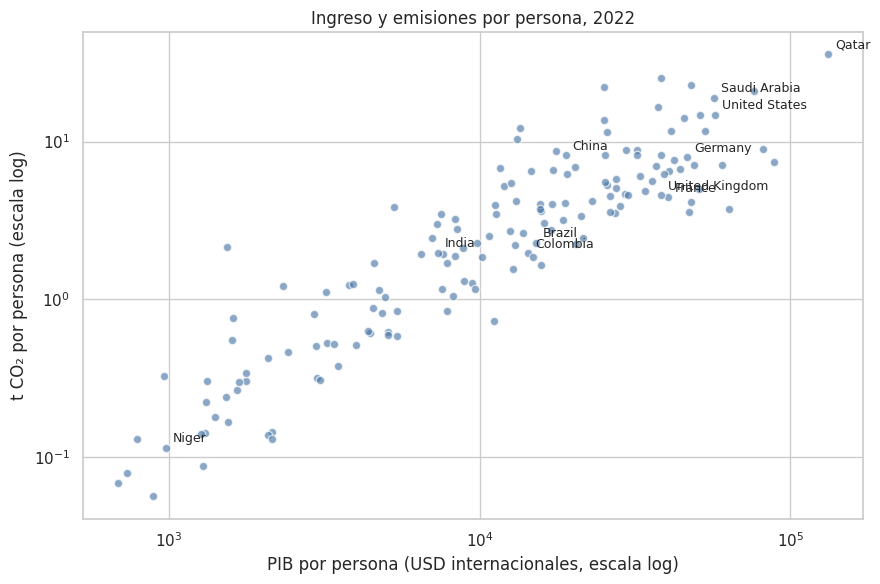

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(actual["gdp_per_capita"], actual["co2_per_capita"], alpha=0.65, color="#4c78a8", edgecolor="white")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("PIB por persona (USD internacionales, escala log)")
ax.set_ylabel("t CO₂ por persona (escala log)")
ax.set_title(f"Ingreso y emisiones por persona, {ultimo_anio}")

etiquetas = ["United States", "China", "India", "France", "United Kingdom", "Germany",
             "Qatar", "Colombia", "Niger", "Brazil", "Saudi Arabia"]
for _, fila in actual[actual["country"].isin(etiquetas)].iterrows():
    ax.annotate(fila["country"], (fila["gdp_per_capita"], fila["co2_per_capita"]),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
plt.tight_layout()
plt.show()

La nube sube en diagonal: más ingreso, más emisiones. Con ejes logarítmicos esa diagonal es casi una recta, que es justo lo que necesita una regresión lineal. También se ve que en un mismo nivel de ingreso hay países muy arriba y otros muy abajo; ahí está la parte de la historia que no explica el dinero.

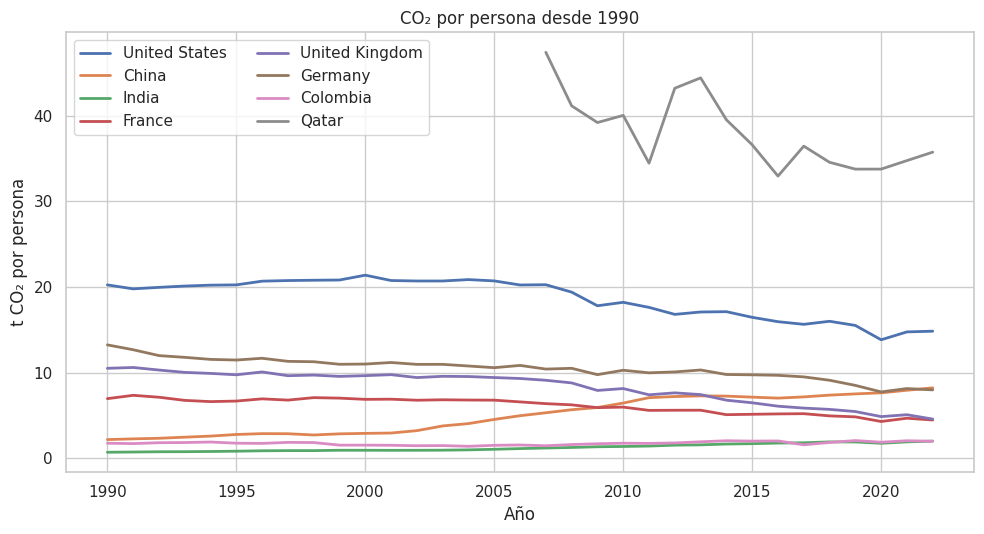

In [8]:
comparar = ["United States", "China", "India", "France", "United Kingdom", "Germany", "Colombia", "Qatar"]
comparar = [p for p in comparar if p in df["country"].unique()]

fig, ax = plt.subplots(figsize=(10, 5.5))
for pais in comparar:
    d = df[df["country"] == pais]
    ax.plot(d["year"], d["co2_per_capita"], label=pais, linewidth=2)
ax.set_title("CO₂ por persona desde 1990")
ax.set_xlabel("Año"); ax.set_ylabel("t CO₂ por persona")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

Estados Unidos, Alemania y Reino Unido bajan con el tiempo mientras China e India suben. Es decir, el mismo nivel de ingreso no implica siempre las mismas emisiones: la relación se desplaza con los años. Más adelante esto aparece como parte del error del modelo.

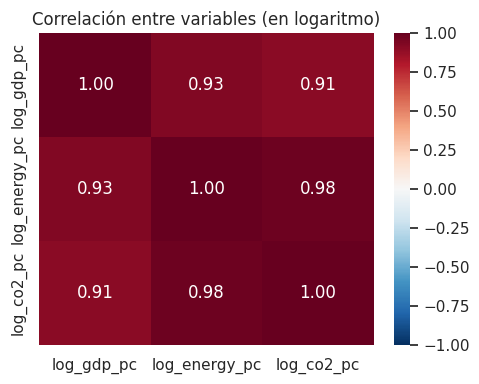

In [9]:
corr = df[["log_gdp_pc", "log_energy_pc", "log_co2_pc"]].corr().round(3)
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlación entre variables (en logaritmo)")
plt.tight_layout()
plt.show()

## 4. Modelo de regresión lineal

Se ajustan dos modelos sobre el logaritmo de las emisiones por persona:

- **Modelo 1:** solo el ingreso por persona.
- **Modelo 2:** ingreso y energía por persona.

Con variables en logaritmo, el coeficiente se lee como una elasticidad: si el ingreso sube 1 %, las emisiones cambian en (coeficiente) %.

La división entre entrenamiento y prueba se hace **por país**, no por fila. Si no, el modelo vería a Francia en 2005 durante el entrenamiento y luego lo evaluaríamos con Francia en 2006, lo que sería casi hacer trampa.

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(gss.split(df, groups=df["country"]))
train, test = df.iloc[idx_train], df.iloc[idx_test]
print(f"Entrenamiento: {train['country'].nunique()} países, {len(train):,} filas")
print(f"Prueba:        {test['country'].nunique()} países, {len(test):,} filas")

def ajustar(variables, nombre):
    modelo = LinearRegression().fit(train[variables], train["log_co2_pc"])
    pred = modelo.predict(test[variables])
    real = test["log_co2_pc"]
    res = {
        "Modelo": nombre,
        "R² (prueba)": r2_score(real, pred),
        "RMSE (log)": np.sqrt(mean_squared_error(real, pred)),
        "Error medio (t CO₂/persona)": mean_absolute_error(np.exp(real), np.exp(pred)),
    }
    return modelo, pred, res

m1, pred1, r1 = ajustar(["log_gdp_pc"], "1. Solo ingreso")
m2, pred2, r2 = ajustar(["log_gdp_pc", "log_energy_pc"], "2. Ingreso + energía")

resultados = pd.DataFrame([r1, r2]).set_index("Modelo").round(3)
resultados

Entrenamiento: 122 países, 3,929 filas
Prueba:        31 países, 983 filas


,R² (prueba),RMSE (log),Error medio (t CO₂/persona)
Modelo,,,
1. Solo ingreso,0.827,0.693,2.201
2. Ingreso + energía,0.970,0.289,0.675


In [11]:
print("Modelo 1")
print(f"  Intercepto: {m1.intercept_:.3f}")
print(f"  Elasticidad del ingreso: {m1.coef_[0]:.3f}")
print("\nModelo 2")
print(f"  Intercepto: {m2.intercept_:.3f}")
print(f"  Elasticidad del ingreso: {m2.coef_[0]:.3f}")
print(f"  Elasticidad de la energía: {m2.coef_[1]:.3f}")

Modelo 1
  Intercepto: -10.362
  Elasticidad del ingreso: 1.227

Modelo 2
  Intercepto: -8.040
  Elasticidad del ingreso: -0.028
  Elasticidad de la energía: 0.979


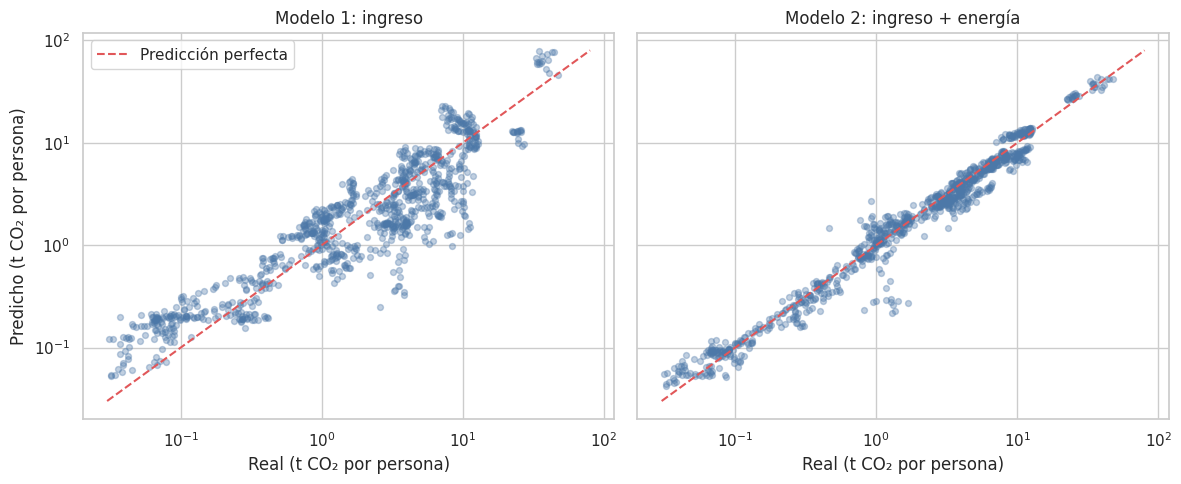

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, pred, titulo in zip(ax, [pred1, pred2], ["Modelo 1: ingreso", "Modelo 2: ingreso + energía"]):
    a.scatter(np.exp(test["log_co2_pc"]), np.exp(pred), alpha=0.35, color="#4c78a8", s=18)
    lim = [0.03, 80]
    a.plot(lim, lim, color="#e15759", linestyle="--", label="Predicción perfecta")
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(titulo); a.set_xlabel("Real (t CO₂ por persona)")
ax[0].set_ylabel("Predicho (t CO₂ por persona)")
ax[0].legend()
plt.tight_layout()
plt.show()

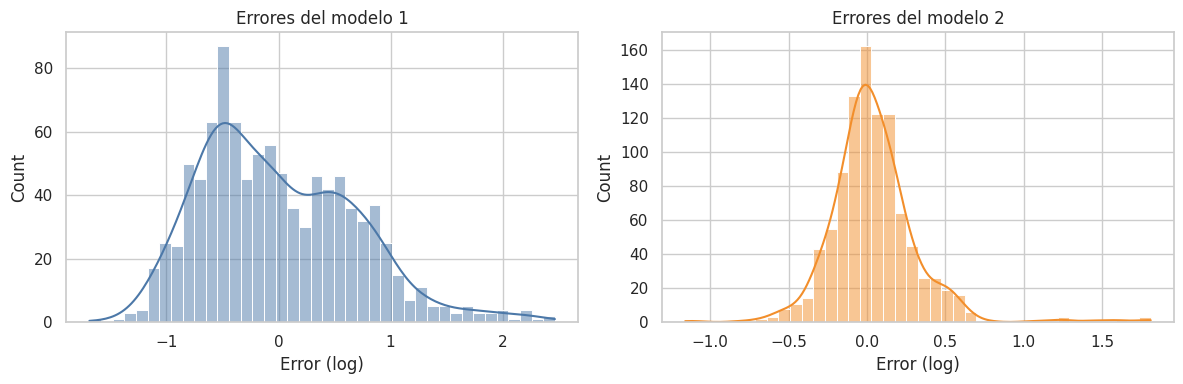

In [13]:
residuos1 = test["log_co2_pc"] - pred1
residuos2 = test["log_co2_pc"] - pred2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuos1, bins=40, kde=True, ax=ax[0], color="#4c78a8")
ax[0].set_title("Errores del modelo 1"); ax[0].set_xlabel("Error (log)")
sns.histplot(residuos2, bins=40, kde=True, ax=ax[1], color="#f28e2b")
ax[1].set_title("Errores del modelo 2"); ax[1].set_xlabel("Error (log)")
plt.tight_layout()
plt.show()

Una regresión lineal funciona bien cuando los errores se reparten alrededor de cero sin sesgo evidente. Si las campanas quedan centradas y razonablemente simétricas, el supuesto aguanta.

## 5. ¿Quién se sale de la línea?

Para ver qué países emiten más o menos de lo que su ingreso sugiere, se reajusta el modelo 1 con todos los datos y se mira el error en el año de referencia. Un error positivo significa que el país emite más de lo esperado para su nivel de ingreso.

In [14]:
final = LinearRegression().fit(df[["log_gdp_pc"]], df["log_co2_pc"])
actual["esperado"] = np.exp(final.predict(actual[["log_gdp_pc"]]))
actual["veces_lo_esperado"] = actual["co2_per_capita"] / actual["esperado"]

cols = ["country", "gdp_per_capita", "co2_per_capita", "esperado", "veces_lo_esperado"]
sobre = actual.nlargest(10, "veces_lo_esperado")[cols]
bajo_esp = actual.nsmallest(10, "veces_lo_esperado")[cols]

print(f"EMITEN MÁS DE LO QUE PREDICE SU INGRESO ({ultimo_anio})")
display(sobre.round(2).reset_index(drop=True))
print(f"\nEMITEN MENOS DE LO QUE PREDICE SU INGRESO ({ultimo_anio})")
display(bajo_esp.round(2).reset_index(drop=True))

EMITEN MÁS DE LO QUE PREDICE SU INGRESO (2022)


,country,gdp_per_capita,co2_per_capita,esperado,veces_lo_esperado
0,North Korea,1537.81,2.14,0.25,8.45
1,Turkmenistan,13485.52,12.25,3.69,3.32
2,Venezuela,5305.43,3.84,1.17,3.29
3,Mongolia,13233.69,10.41,3.60,2.89
4,Syria,2330.72,1.22,0.42,2.88
5,Zimbabwe,1611.89,0.76,0.27,2.84
6,Trinidad and Tobago,25077.08,22.20,7.93,2.80
7,Mozambique,962.81,0.32,0.14,2.29
8,South Africa,11599.51,6.79,3.06,2.22
9,Yemen,1592.06,0.55,0.26,2.07



EMITEN MENOS DE LO QUE PREDICE SU INGRESO (2022)


,country,gdp_per_capita,co2_per_capita,esperado,veces_lo_esperado
0,Switzerland,63623.01,3.75,25.01,0.15
1,Norway,88390.41,7.48,37.52,0.20
2,Sweden,47124.89,3.56,17.27,0.21
3,Hong Kong,47775.87,4.12,17.56,0.23
4,Sri Lanka,11156.08,0.72,2.92,0.25
5,Singapore,81736.33,8.92,34.07,0.26
6,Denmark,50725.74,5.01,18.91,0.26
7,Ireland,60350.30,7.15,23.43,0.30
8,France,40308.89,4.45,14.24,0.31
9,Uganda,2155.77,0.13,0.38,0.34


In [15]:
europa = ["France", "United Kingdom", "Portugal", "Germany", "Netherlands", "Belgium"]
tabla_eu = actual[actual["country"].isin(europa)][cols].sort_values("veces_lo_esperado")
display(tabla_eu.round(2).reset_index(drop=True))

,country,gdp_per_capita,co2_per_capita,esperado,veces_lo_esperado
0,France,40308.89,4.45,14.24,0.31
1,United Kingdom,38358.12,4.55,13.40,0.34
2,Netherlands,49128.04,7.07,18.18,0.39
3,Portugal,28387.33,3.90,9.24,0.42
4,Germany,46495.28,7.97,16.99,0.47
5,Belgium,42062.04,7.63,15.01,0.51


## 6. Interpretación

In [16]:
b1 = m1.coef_[0]
b2_ing, b2_en = m2.coef_
r2_1, r2_2 = r1["R² (prueba)"], r2["R² (prueba)"]
err1, err2 = r1["Error medio (t CO₂/persona)"], r2["Error medio (t CO₂/persona)"]

print(f"1. El ingreso solo explica el {r2_1*100:.0f}% de las diferencias en emisiones por persona entre países que el modelo no había visto.")
print(f"   Cada 10% más de ingreso por persona se asocia con un {b1*10:.1f}% más de CO₂ por persona.")
print()
print(f"2. Al sumar la energía, el modelo pasa a explicar el {r2_2*100:.0f}% y el error medio baja de {err1:.1f} a {err2:.1f} toneladas por persona.")
print(f"   Con la energía dentro, el efecto del ingreso cae a {b2_ing:.2f}: buena parte de lo que parecía 'efecto del dinero' era en realidad consumo de energía.")
print()
if b2_en > 0.9:
    print(f"3. La energía casi se traduce uno a uno en CO₂ (coeficiente {b2_en:.2f}). Lo que cambia entre países es cuánto de esa energía viene de quemar combustibles fósiles.")
else:
    print(f"3. Un 10% más de energía por persona se asocia con un {b2_en*10:.1f}% más de CO₂ por persona. El resto depende de qué combustible se quema.")
print()
fr = actual[actual['country'] == 'France']['veces_lo_esperado']
de = actual[actual['country'] == 'Germany']['veces_lo_esperado']
if len(fr) and len(de):
    msg = f"4. En {ultimo_anio}, Francia emite {fr.iloc[0]:.2f} veces lo que predice su ingreso y Alemania {de.iloc[0]:.2f}. "
    if fr.iloc[0] < de.iloc[0]:
        msg += "Es la diferencia que el artículo atribuye a la mezcla eléctrica."
    else:
        msg += "Aquí el resultado no sigue lo que cuenta el artículo, y vale la pena revisar el año y las variables antes de sacar conclusiones."
    print(msg)

1. El ingreso solo explica el 83% de las diferencias en emisiones por persona entre países que el modelo no había visto.
   Cada 10% más de ingreso por persona se asocia con un 12.3% más de CO₂ por persona.

2. Al sumar la energía, el modelo pasa a explicar el 97% y el error medio baja de 2.2 a 0.7 toneladas por persona.
   Con la energía dentro, el efecto del ingreso cae a -0.03: buena parte de lo que parecía 'efecto del dinero' era en realidad consumo de energía.

3. La energía casi se traduce uno a uno en CO₂ (coeficiente 0.98). Lo que cambia entre países es cuánto de esa energía viene de quemar combustibles fósiles.

4. En 2022, Francia emite 0.31 veces lo que predice su ingreso y Alemania 0.47. Es la diferencia que el artículo atribuye a la mezcla eléctrica.


**Lo que dicen los números junto con el artículo**

El ingreso empuja las emisiones hacia arriba, y con fuerza, pero deja sin explicar una parte grande. Lo que sobra no es ruido: los países que emiten mucho más de lo que su ingreso predice son, casi siempre, grandes productores de petróleo y gas, donde la energía es barata y se quema sin demasiado ahorro. Los que emiten mucho menos tienen electricidad nuclear, hidroeléctrica o renovable, o una economía poco intensiva en energía.

Eso confirma la frase central del artículo: la prosperidad es el principal motor de las emisiones, pero las decisiones de política y tecnología importan. Francia, Reino Unido y Portugal producen una parte mucho mayor de su electricidad con nuclear y renovables que Alemania, y se nota en la tabla de Europa de la sección anterior.

El segundo modelo lo deja más claro: con la energía por persona en la ecuación, el peso del ingreso se reduce (el número exacto está en la celda anterior). El dinero no contamina por sí solo; lo hace la energía que el dinero compra y la fuente de la que sale.

**Límites del análisis**

- Son emisiones de producción, es decir, las que ocurren dentro de las fronteras del país. No descuentan lo que se importa, y un país rico que compra su acero y sus fábricas en China se ve mejor de lo que realmente es.
- El modelo describe asociaciones. No demuestra que subir el ingreso en un país concreto produzca exactamente ese aumento de CO₂, y el artículo mismo muestra con la serie temporal que muchos países ricos ya bajan emisiones mientras crecen.
- Los años cuentan. Un mismo ingreso emitía más en 1990 que ahora, así que un modelo que ignora el año mezcla épocas distintas.
- Los datos de energía y emisiones son menos precisos en países pequeños o con estadísticas débiles, y el artículo estima la incertidumbre global entre 2 % y 5 %.

**Siguiente paso posible:** repetir el modelo agregando el año o la proporción de electricidad de origen fósil, y comprobar cuánto de la brecha entre Francia y Alemania se cierra.

## 7. Aporte individual: evolución de las emisiones de CO₂ por habitante en Colombia

Esta sección complementa la investigación del grupo, que estudia las emisiones de CO₂ por habitante y su relación con el nivel de ingreso y el consumo de energía. El aporte individual consiste en profundizar en un caso: **Colombia**.

La pregunta de análisis es:

**¿Cómo han evolucionado las emisiones de CO₂ por habitante en Colombia desde 1990 y cómo se comparan con el promedio mundial?**

Se utiliza el indicador **CO₂ emissions per capita** de Our World in Data, expresado en toneladas de CO₂ por persona al año. Según la definición de la plataforma, el indicador incluye las emisiones procedentes de la quema de combustibles fósiles y procesos industriales —como transporte, generación eléctrica y calefacción—, pero no incluye el cambio de uso del suelo. Las emisiones son territoriales: se contabilizan en el país donde se producen, no donde se consumen los bienes.

**Fuente de datos:** Our World in Data, gráfico “CO₂ emissions per capita”, basado en Global Carbon Project y datos de población. La descarga se realiza directamente desde el archivo CSV del gráfico para trabajar con el indicador exacto seleccionado en el artículo.

Este análisis permite complementar la comparación entre países con una revisión histórica de Colombia. No busca demostrar causalidad, sino describir la trayectoria y estimar una tendencia lineal en el periodo disponible.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Descarga directa del indicador seleccionado en Our World in Data:
# CO2 emissions per capita (toneladas por persona)
url_co2 = "https://ourworldindata.org/grapher/co-emissions-per-capita.csv?v=1&csvType=full&useColumnShortNames=false"
datos_co2 = pd.read_csv(url_co2, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})

# Identificar las columnas publicadas por Our World in Data y estandarizar sus nombres
col_entidad = "Entity" if "Entity" in datos_co2.columns else "country"
col_anio = "Year" if "Year" in datos_co2.columns else "year"
col_indicador = [c for c in datos_co2.columns if ("per capita" in c.lower() or "per person" in c.lower()) and ("co2" in c.lower() or "co₂" in c.lower())]

if not col_indicador:
    raise ValueError("No se identificó la columna de emisiones por persona. Revise las columnas descargadas: " + str(datos_co2.columns.tolist()))

datos_co2 = datos_co2[[col_entidad, col_anio, col_indicador[0]]].copy()
datos_co2.columns = ["country", "year", "co2_per_capita"]

datos_co2["year"] = pd.to_numeric(datos_co2["year"], errors="coerce")
datos_co2["co2_per_capita"] = pd.to_numeric(datos_co2["co2_per_capita"], errors="coerce")

# Seleccionar Colombia y el agregado mundial desde 1990
serie = datos_co2[
    datos_co2["country"].isin(["Colombia", "World"]) &
    (datos_co2["year"] >= 1990)
].dropna(subset=["year", "co2_per_capita"]).copy()

serie["year"] = serie["year"].astype(int)
serie = serie.sort_values(["country", "year"])

colombia = serie[serie["country"] == "Colombia"].copy()
mundo = serie[serie["country"] == "World"].copy()

if colombia.empty or mundo.empty:
    raise ValueError("No se encontraron registros de Colombia o del mundo en la descarga.")

print("Fuente: Our World in Data – CO₂ emissions per capita")
print("Años disponibles para Colombia:", colombia["year"].min(), "-", colombia["year"].max())
print("Cantidad de registros de Colombia:", len(colombia))
print("Cantidad de registros del mundo:", len(mundo))
display(colombia.tail())

Fuente: Our World in Data – CO₂ emissions per capita
Años disponibles para Colombia: 1990 - 2025
Cantidad de registros de Colombia: 36
Cantidad de registros del mundo: 36


,country,year,co2_per_capita
5236,Colombia,2021,2.020288
5237,Colombia,2022,1.962655
5238,Colombia,2023,2.013507
5239,Colombia,2024,2.009750
5240,Colombia,2025,1.798143


### 7.1. Comportamiento de las emisiones en Colombia

Primero se observa la evolución anual del indicador. La gráfica permite identificar periodos de aumento, disminución o estabilidad, sin asumir de antemano que la tendencia sea siempre creciente.

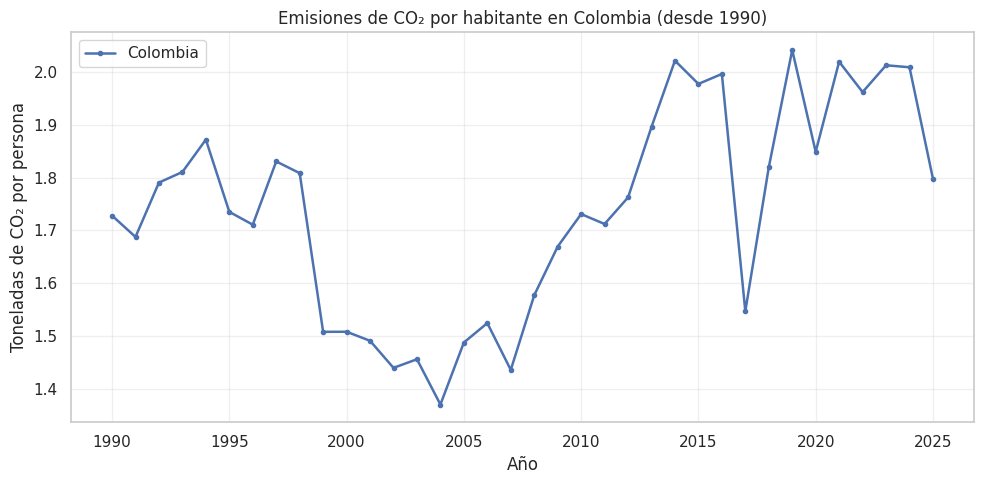

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(colombia["year"], colombia["co2_per_capita"],
         marker="o", markersize=3, linewidth=1.8,
         label="Colombia")
plt.title("Emisiones de CO₂ por habitante en Colombia (desde 1990)")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO₂ por persona")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 7.2. Comparación de Colombia con el promedio mundial

Se comparan las toneladas de CO₂ por habitante de Colombia con el valor mundial para los mismos años disponibles. Esta comparación es descriptiva: muestra diferencias entre los dos indicadores, pero no explica por sí sola sus causas.

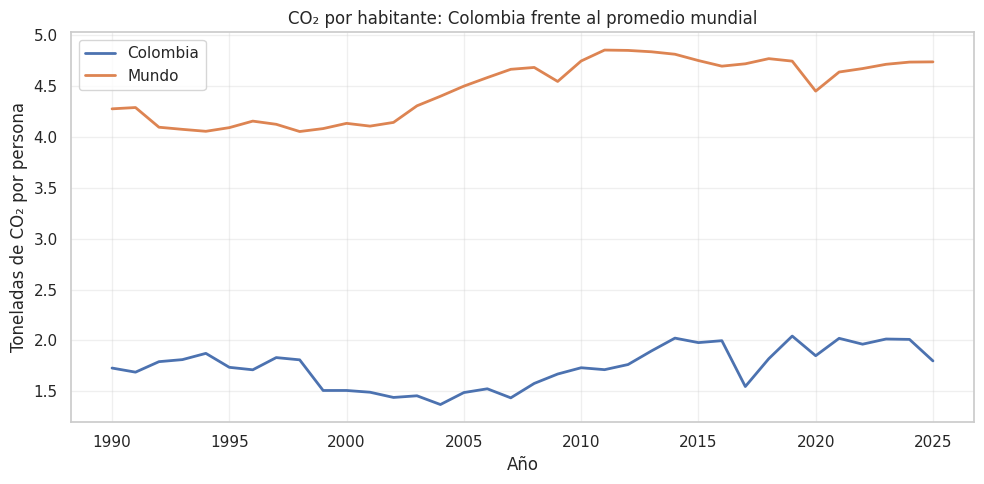

Último año común: 2025
Colombia: 1.798 toneladas por persona
Mundo: 4.737 toneladas por persona
Diferencia Colombia - mundo: -2.939 toneladas por persona


In [19]:
comparacion = colombia.merge(
    mundo, on="year", how="inner", suffixes=("_colombia", "_mundo")
)

plt.figure(figsize=(10, 5))
plt.plot(comparacion["year"], comparacion["co2_per_capita_colombia"],
         linewidth=2, label="Colombia")
plt.plot(comparacion["year"], comparacion["co2_per_capita_mundo"],
         linewidth=2, label="Mundo")
plt.title("CO₂ por habitante: Colombia frente al promedio mundial")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO₂ por persona")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Diferencia entre Colombia y el mundo en el último año común
ultimo = comparacion.iloc[-1]
print("Último año común:", int(ultimo["year"]))
print("Colombia:", round(ultimo["co2_per_capita_colombia"], 3), "toneladas por persona")
print("Mundo:", round(ultimo["co2_per_capita_mundo"], 3), "toneladas por persona")
print("Diferencia Colombia - mundo:",
      round(ultimo["co2_per_capita_colombia"] - ultimo["co2_per_capita_mundo"], 3),
      "toneladas por persona")

### 7.3. Resumen estadístico y cambio porcentual

Se calculan medidas sencillas para describir la serie colombiana: promedio, mínimo, máximo y variación porcentual entre el primer y el último año disponible. La variación porcentual compara los extremos del periodo y no significa que el cambio haya ocurrido de manera uniforme cada año.

In [20]:
primer_registro = colombia.iloc[0]
ultimo_registro = colombia.iloc[-1]

valor_inicial = primer_registro["co2_per_capita"]
valor_final = ultimo_registro["co2_per_capita"]

variacion_porcentual = ((valor_final - valor_inicial) / valor_inicial) * 100

resumen_colombia = pd.DataFrame({
    "Indicador": [
        "Año inicial", "Año final", "Promedio del periodo",
        "Valor mínimo", "Valor máximo", "Variación porcentual"
    ],
    "Resultado": [
        int(primer_registro["year"]),
        int(ultimo_registro["year"]),
        round(colombia["co2_per_capita"].mean(), 3),
        round(colombia["co2_per_capita"].min(), 3),
        round(colombia["co2_per_capita"].max(), 3),
        round(variacion_porcentual, 2)
    ]
})
display(resumen_colombia)

anio_min = colombia.loc[colombia["co2_per_capita"].idxmin(), "year"]
anio_max = colombia.loc[colombia["co2_per_capita"].idxmax(), "year"]
print(f"El menor valor se registró en {int(anio_min)}.")
print(f"El mayor valor se registró en {int(anio_max)}.")

,Indicador,Resultado
0,Año inicial,1990.000
1,Año final,2025.000
2,Promedio del periodo,1.739
3,Valor mínimo,1.370
4,Valor máximo,2.042
5,Variación porcentual,4.050


El menor valor se registró en 2004.
El mayor valor se registró en 2019.


### 7.4. Tendencia lineal de las emisiones colombianas

Como complemento, se ajusta una regresión lineal sencilla entre el año y las emisiones por habitante. El coeficiente indica el cambio promedio estimado en toneladas por persona por cada año adicional, dentro del periodo analizado. Este modelo resume una tendencia; no demuestra que el paso del tiempo sea la causa de los cambios ni permite hacer predicciones seguras a largo plazo.

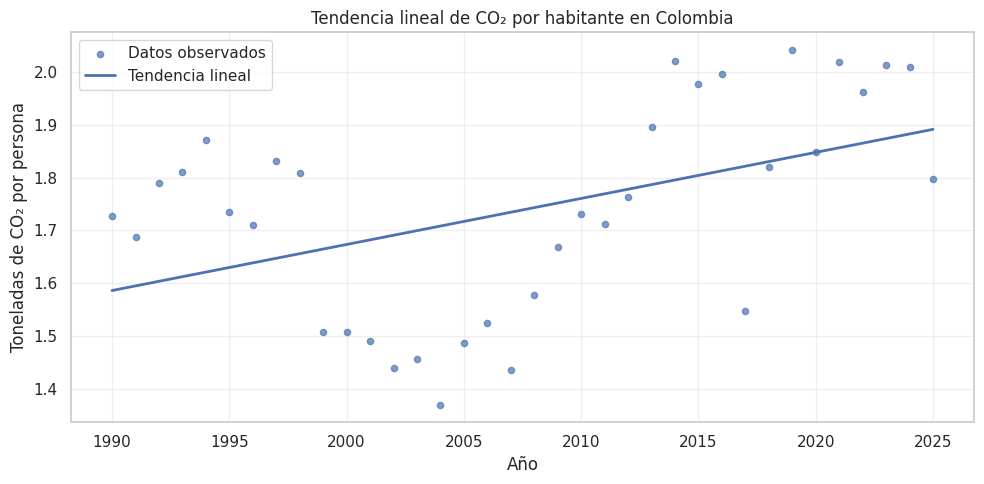

Cambio promedio estimado: 0.0087 toneladas por persona al año
R² de la tendencia lineal: 0.210
La tendencia lineal estimada es creciente durante el periodo.


In [21]:
X = colombia[["year"]]
y = colombia["co2_per_capita"]

modelo_colombia = LinearRegression()
modelo_colombia.fit(X, y)
prediccion = modelo_colombia.predict(X)

pendiente = modelo_colombia.coef_[0]
r2_colombia = modelo_colombia.score(X, y)

plt.figure(figsize=(10, 5))
plt.scatter(colombia["year"], y, s=20, alpha=0.7, label="Datos observados")
plt.plot(colombia["year"], prediccion, linewidth=2, label="Tendencia lineal")
plt.title("Tendencia lineal de CO₂ por habitante en Colombia")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO₂ por persona")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Cambio promedio estimado: {pendiente:.4f} toneladas por persona al año")
print(f"R² de la tendencia lineal: {r2_colombia:.3f}")

if pendiente > 0:
    print("La tendencia lineal estimada es creciente durante el periodo.")
elif pendiente < 0:
    print("La tendencia lineal estimada es decreciente durante el periodo.")
else:
    print("La tendencia lineal estimada es prácticamente estable.")

### 7.5. Interpretación del aporte

La serie histórica permite estudiar el comportamiento de las emisiones de CO₂ por habitante de Colombia y compararlo con el promedio mundial. El resumen estadístico identifica los valores extremos y la variación entre el primer y el último año disponible. La regresión lineal complementa la descripción al estimar la dirección y magnitud promedio de la tendencia temporal.

Para interpretar los resultados se deben tener en cuenta tres aspectos:

- El indicador está expresado en toneladas por persona, por lo que permite comparar países de distinto tamaño poblacional.
- Son emisiones territoriales de CO₂ procedentes de combustibles fósiles y procesos industriales; no representan todos los gases de efecto invernadero ni incluyen el cambio de uso del suelo.
- La tendencia temporal muestra asociación con el año, pero no identifica las causas de los cambios. Factores como la actividad económica, el transporte, la generación eléctrica y la estructura productiva pueden influir y requerirían variables adicionales para estudiarse.

**Conclusión de esta sección:** el caso colombiano complementa el análisis internacional del grupo porque permite observar la trayectoria de un país concreto y ubicarla frente al promedio mundial. Las conclusiones definitivas deben redactarse con los valores y el periodo que aparezcan al ejecutar el notebook con la descarga actualizada de Our World in Data.

**Referencia del indicador:** Our World in Data, “CO₂ emissions per capita”. https://ourworldindata.org/grapher/co-emissions-per-capita
**Artículo principal:** Our World in Data, “CO₂ emissions”. https://ourworldindata.org/co2-emissions
